## Importing Libraries

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading Dataset

In [76]:
actual_dataset = pd.read_csv("../dataset/food_waste_dataset.csv")

In [77]:
actual_dataset.head()

,Inventory_ID,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Promotion,Weather,Waste_Quantity,Waste_Reason,Donation_Made,Waste_Level
0,INV000001,2025-01-01,Restaurant,Bakery,77,77,0,4.0,20.4,77.0,No,Sunny,0,No Waste,No,Low
1,INV000002,2025-01-01,Cafeteria,Bakery,75,53,22,3.0,22.8,53.0,No,Cloudy,6,Low Demand,No,Medium
2,INV000003,2025-01-01,Supermarket,Fruits,176,159,17,6.0,12.4,159.0,No,Sunny,4,Expired,No,Medium
3,INV000004,2025-01-01,Cafeteria,Dairy,58,58,0,7.0,3.5,83.0,Yes,Cloudy,0,No Waste,No,Low
4,INV000005,2025-01-01,Restaurant,Fruits,85,85,0,3.0,3.3,87.0,No,Hot,0,No Waste,No,Low


In [78]:
## creating copy so actual_dataset remains preserved
## all the data cleaning will be now performed on df
df = actual_dataset.copy()

In [79]:
df.head()

,Inventory_ID,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Promotion,Weather,Waste_Quantity,Waste_Reason,Donation_Made,Waste_Level
0,INV000001,2025-01-01,Restaurant,Bakery,77,77,0,4.0,20.4,77.0,No,Sunny,0,No Waste,No,Low
1,INV000002,2025-01-01,Cafeteria,Bakery,75,53,22,3.0,22.8,53.0,No,Cloudy,6,Low Demand,No,Medium
2,INV000003,2025-01-01,Supermarket,Fruits,176,159,17,6.0,12.4,159.0,No,Sunny,4,Expired,No,Medium
3,INV000004,2025-01-01,Cafeteria,Dairy,58,58,0,7.0,3.5,83.0,Yes,Cloudy,0,No Waste,No,Low
4,INV000005,2025-01-01,Restaurant,Fruits,85,85,0,3.0,3.3,87.0,No,Hot,0,No Waste,No,Low


## EDA

In [80]:
df.columns

Index(['Inventory_ID', 'Date', 'Business_Type', 'Food_Category',
       'Purchase_Quantity', 'Units_Sold', 'Remaining_Stock', 'Shelf_Life_Days',
       'Storage_Temperature', 'Daily_Demand', 'Promotion', 'Weather',
       'Waste_Quantity', 'Waste_Reason', 'Donation_Made', 'Waste_Level'],
      dtype='str')

In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Inventory_ID         8000 non-null   str    
 1   Date                 8000 non-null   str    
 2   Business_Type        8000 non-null   str    
 3   Food_Category        8000 non-null   str    
 4   Purchase_Quantity    8000 non-null   int64  
 5   Units_Sold           8000 non-null   int64  
 6   Remaining_Stock      8000 non-null   int64  
 7   Shelf_Life_Days      7765 non-null   float64
 8   Storage_Temperature  7814 non-null   float64
 9   Daily_Demand         7790 non-null   float64
 10  Promotion            8000 non-null   str    
 11  Weather              7797 non-null   str    
 12  Waste_Quantity       8000 non-null   int64  
 13  Waste_Reason         8000 non-null   str    
 14  Donation_Made        7767 non-null   str    
 15  Waste_Level          8000 non-null   str    
dtyp

In [82]:
df.describe()

,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Waste_Quantity
count,8000.000000,8000.000000,8000.000000,7765.000000,7814.000000,7790.000000,8000.000000
mean,118.288750,96.959625,21.329125,4.364585,10.450064,105.099358,5.772375
std,58.685297,39.282291,41.663906,2.598122,8.431281,45.162475,16.450741
min,35.000000,26.000000,0.000000,1.000000,-4.400000,26.000000,0.000000
25%,80.000000,67.000000,0.000000,2.000000,3.700000,71.000000,0.000000
50%,104.000000,87.000000,9.000000,4.000000,7.500000,94.000000,1.000000
75%,148.000000,121.000000,30.000000,6.000000,18.100000,132.000000,7.000000
max,968.000000,284.000000,858.000000,14.000000,36.600000,316.000000,447.000000


In [83]:
df.shape

(8000, 16)

In [84]:
df.duplicated().sum()

np.int64(0)

In [85]:
df.isnull().sum()

Inventory_ID             0
Date                     0
Business_Type            0
Food_Category            0
Purchase_Quantity        0
Units_Sold               0
Remaining_Stock          0
Shelf_Life_Days        235
Storage_Temperature    186
Daily_Demand           210
Promotion                0
Weather                203
Waste_Quantity           0
Waste_Reason             0
Donation_Made          233
Waste_Level              0
dtype: int64

In [86]:
## Correlation
df.corr(numeric_only=True)

,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Waste_Quantity
Purchase_Quantity,1.000000,0.705156,0.743693,-0.014247,-0.006900,0.590697,0.692416
Units_Sold,0.705156,1.000000,0.050403,-0.006647,-0.014005,0.933102,0.034529
Remaining_Stock,0.743693,0.050403,1.000000,-0.013794,0.003411,-0.045379,0.942740
Shelf_Life_Days,-0.014247,-0.006647,-0.013794,1.000000,-0.492764,-0.003875,-0.103221
Storage_Temperature,-0.006900,-0.014005,0.003411,-0.492764,1.000000,-0.018918,0.073229
Daily_Demand,0.590697,0.933102,-0.045379,-0.003875,-0.018918,1.000000,-0.030406
Waste_Quantity,0.692416,0.034529,0.942740,-0.103221,0.073229,-0.030406,1.000000


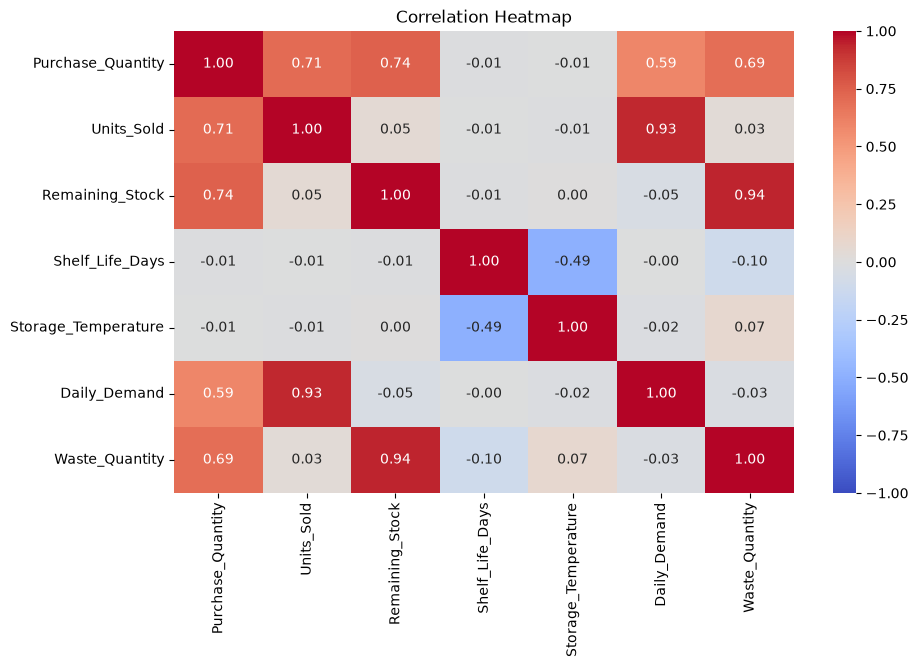

In [87]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1
)
plt.title("Correlation Heatmap")
plt.show()

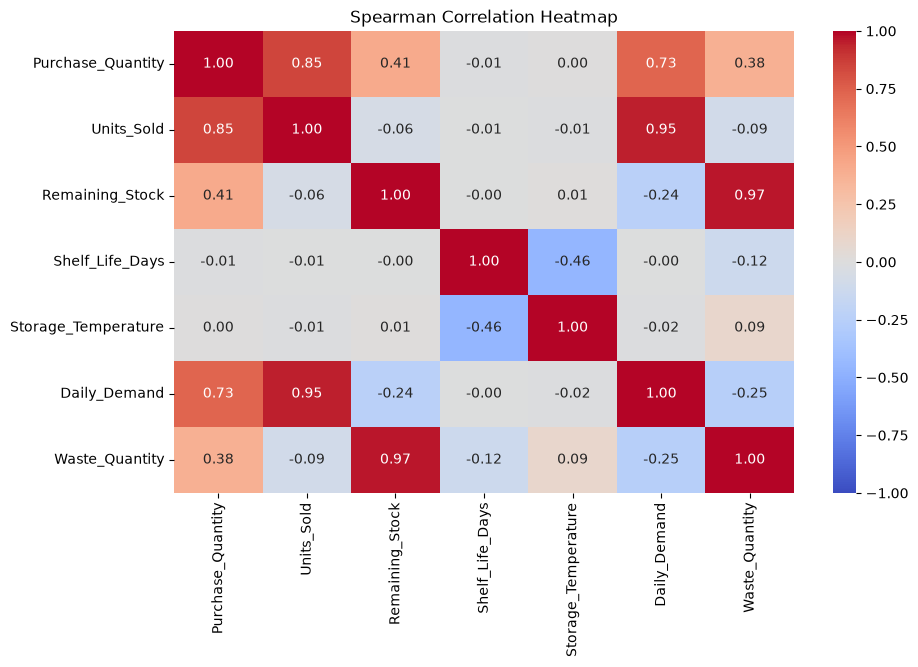

In [88]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(numeric_only=True, method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

plt.title("Spearman Correlation Heatmap")
plt.show()

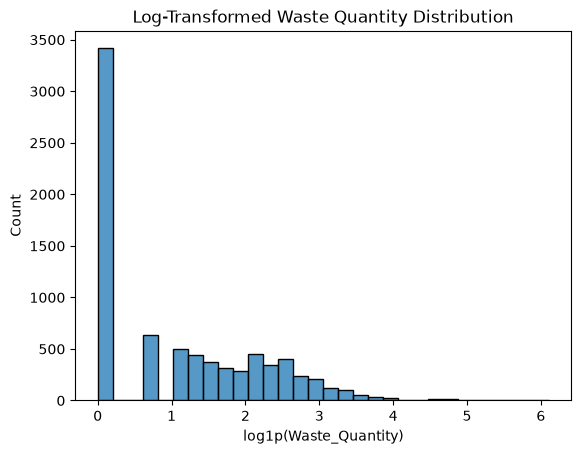

In [89]:
## Visualization
sns.histplot(x=np.log1p(df["Waste_Quantity"]), bins=30)

plt.xlabel("log1p(Waste_Quantity)")
plt.title("Log-Transformed Waste Quantity Distribution")
plt.show()

<Axes: xlabel='Waste_Quantity', ylabel='Count'>

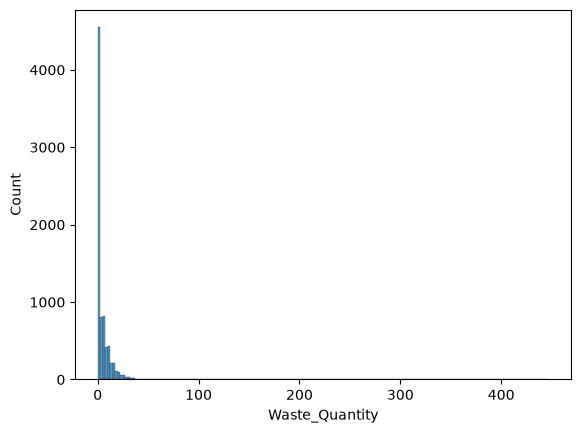

In [90]:
sns.histplot(df["Waste_Quantity"])

<Axes: xlabel='Weather', ylabel='Daily_Demand'>

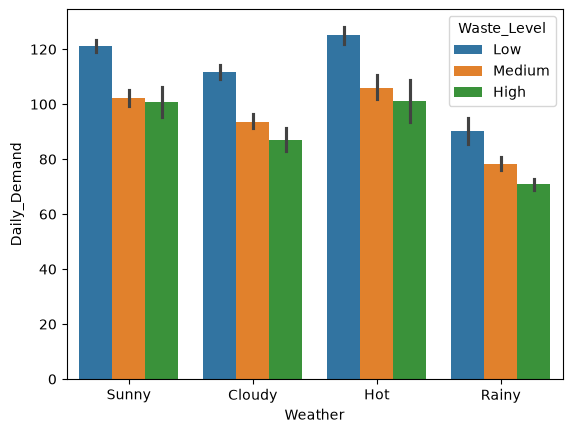

In [91]:
sns.barplot(data=df, x="Weather", y="Daily_Demand", hue="Waste_Level")

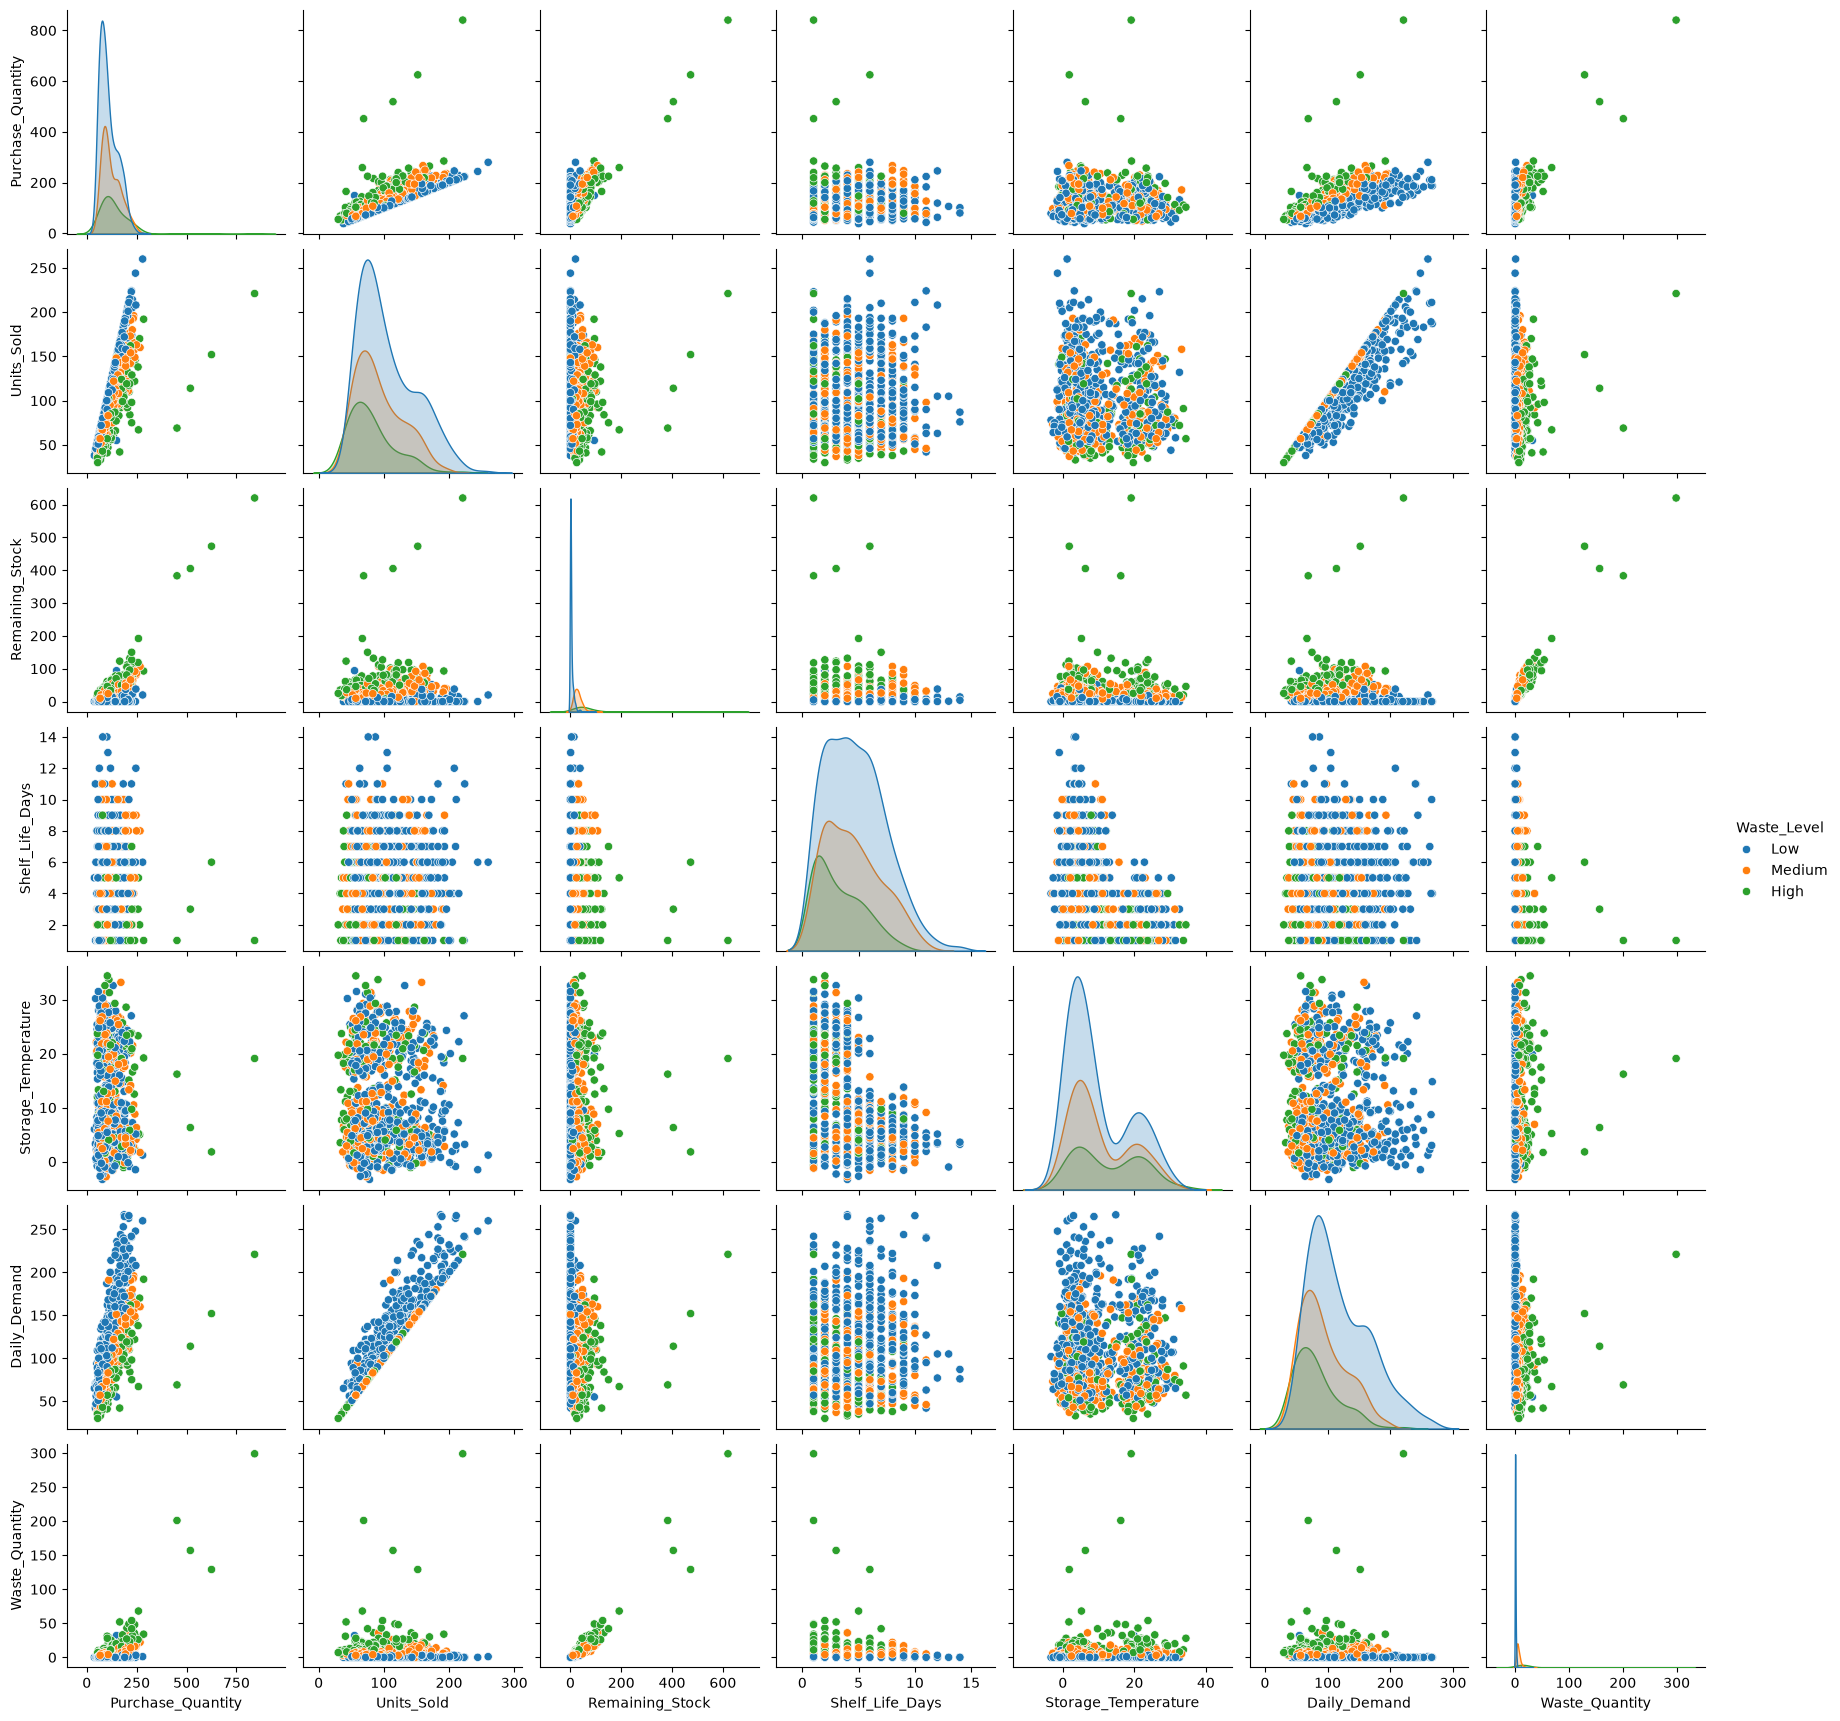

In [92]:
sns.pairplot(df.sample(1000), hue="Waste_Level")

<Axes: xlabel='Waste_Level', ylabel='Shelf_Life_Days'>

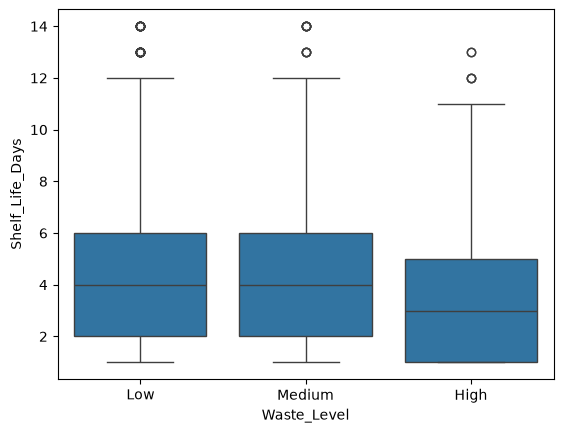

In [93]:
sns.boxplot(data=df, x="Waste_Level", y="Shelf_Life_Days")

<Axes: xlabel='Shelf_Life_Days', ylabel='Count'>

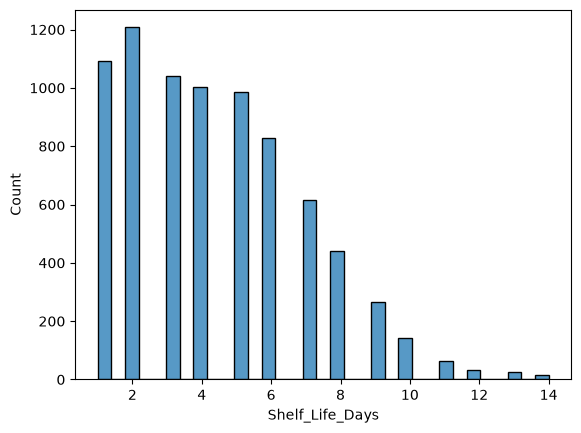

In [94]:
sns.histplot(data=df, x="Shelf_Life_Days")

<Axes: xlabel='Storage_Temperature', ylabel='Count'>

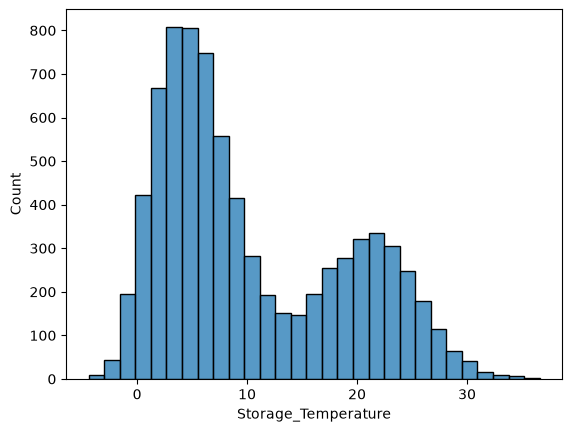

In [95]:
sns.histplot(data=df, x="Storage_Temperature")

In [96]:
df.columns
required_columns = [
    "Business_Type",
    "Food_Category",
    "Purchase_Quantity",
    "Units_Sold",
    "Remaining_Stock",
    "Shelf_Life_Days",
    "Storage_Temperature",
    "Daily_Demand",
    "Promotion",
    "Weather",
    "Waste_Reason",
    "Donation_Made",
]

In [97]:
order = ["Low", "Medium", "High"]
cat_cols = [
    "Business_Type",
    "Food_Category",
    "Promotion",
    "Weather",
    "Waste_Reason",
    "Donation_Made",
]
num_cols = [
    "Purchase_Quantity",
    "Units_Sold",
    "Remaining_Stock",
    "Shelf_Life_Days",
    "Storage_Temperature",
    "Daily_Demand",
]

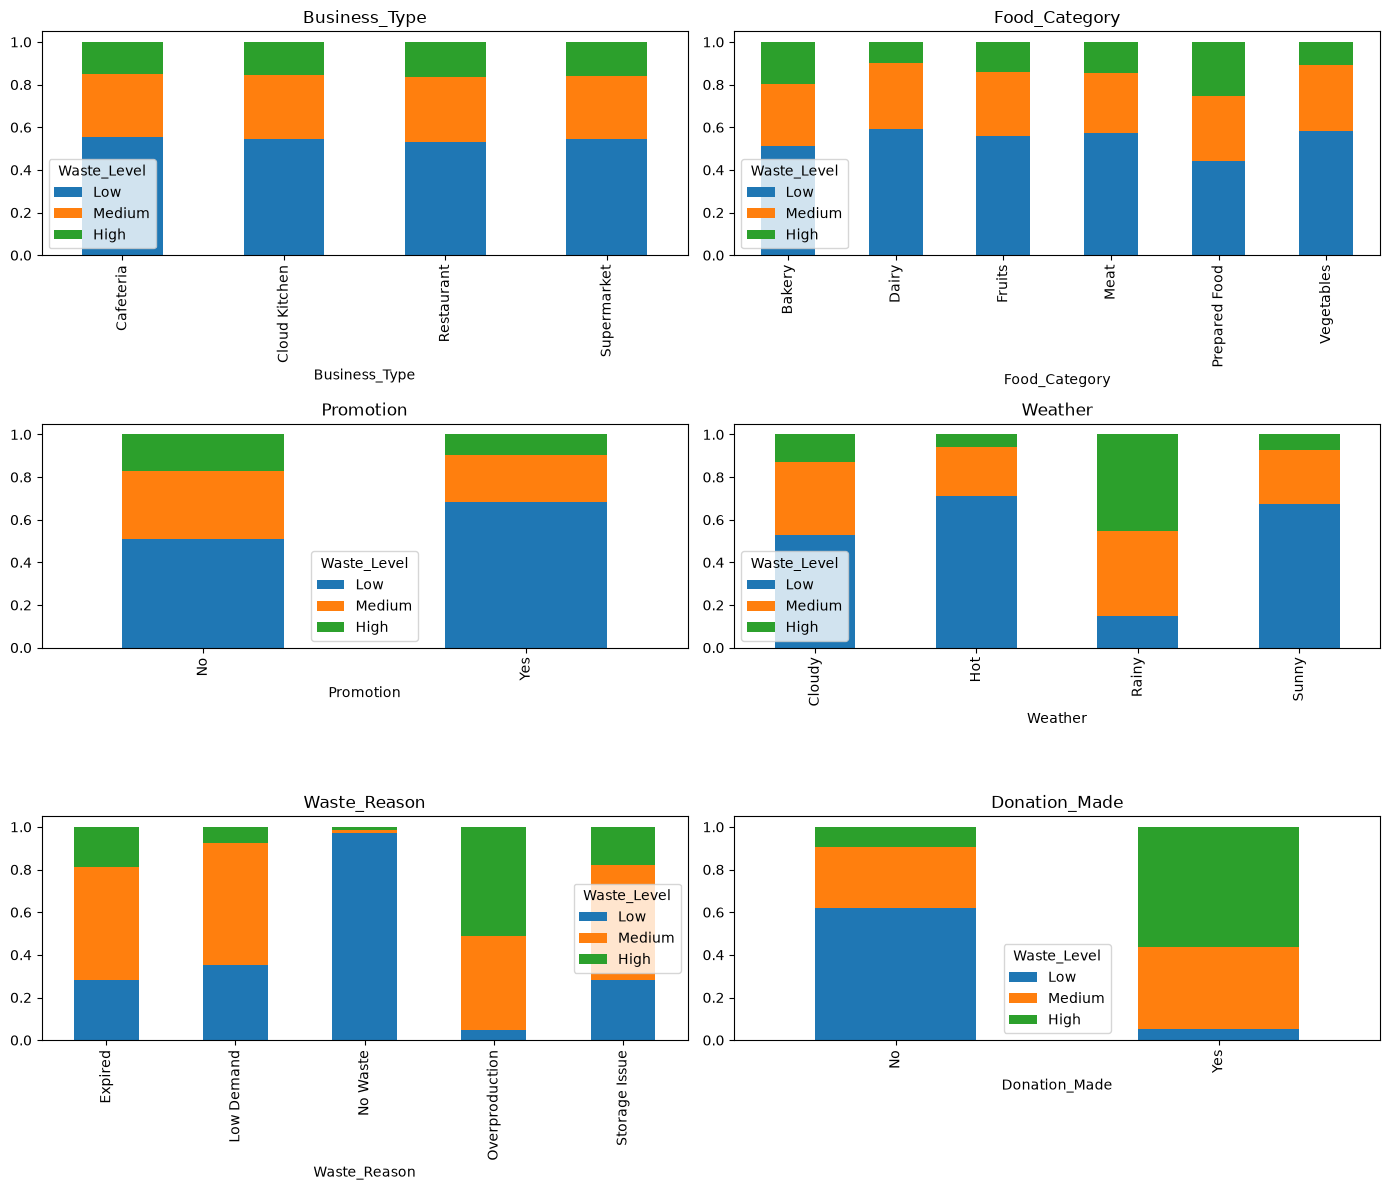

In [98]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, col in zip(axes.flat, cat_cols):
    pd.crosstab(df[col], df["Waste_Level"], normalize="index")[order].plot(
        kind="bar", stacked=True, ax=ax, title=col
    )
plt.tight_layout()

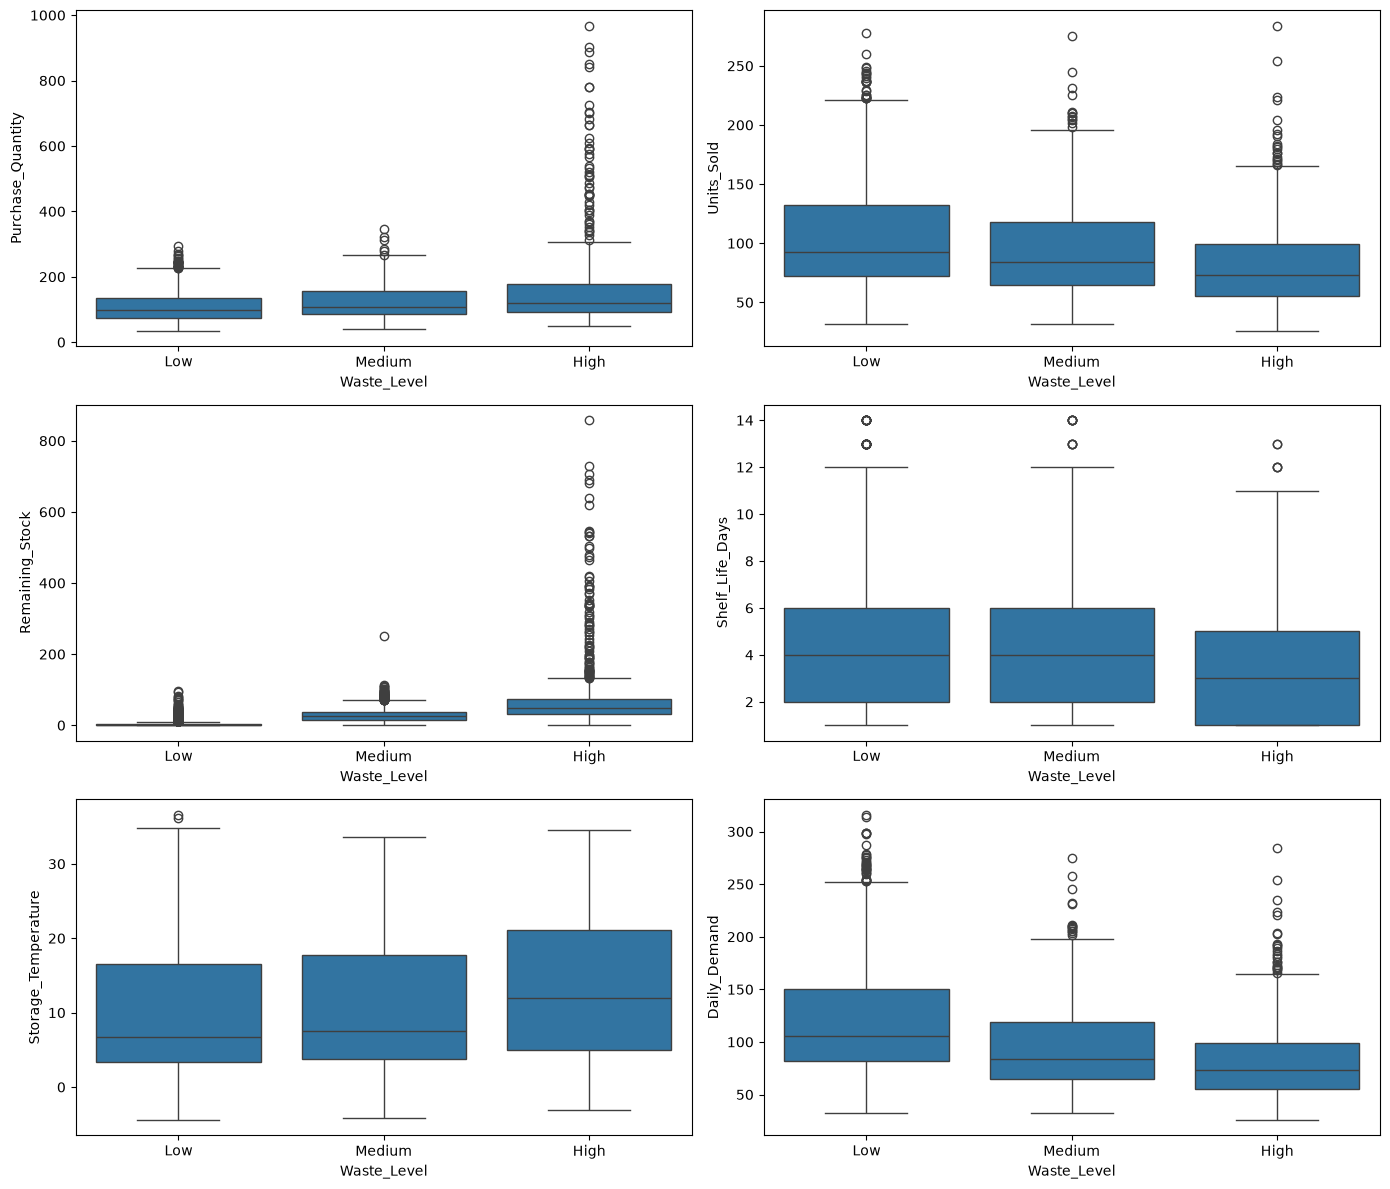

In [99]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="Waste_Level", y=col, order=order, ax=ax)
plt.tight_layout()

In [100]:
pd.crosstab(df["Business_Type"], df["Waste_Level"], normalize="index") * 100

## The proportion of high-waste records remains approximately 15–17% -> Business_Type has a limited association with Waste_Level in this dataset.

Waste_Level,High,Low,Medium
Business_Type,,,
Cafeteria,15.076336,55.343511,29.580153
Cloud Kitchen,15.487572,54.429573,30.082855
Restaurant,16.578411,52.993890,30.427699
Supermarket,16.014975,54.326123,29.658902


In [101]:
zero_waste = df[df["Waste_Quantity"] == 0]

pd.crosstab(zero_waste["Waste_Reason"], zero_waste["Waste_Level"])

# data quality issue -> with Waste_Reason as No Waste -> the there are 104 rows with High and Medium Waste_Level

Waste_Level,High,Low,Medium
Waste_Reason,,,
No Waste,54,3311,50


In [102]:
print(df["Inventory_ID"].is_unique, df.drop(columns="Inventory_ID").duplicated().sum())
print(
    (df["Remaining_Stock"] == df["Purchase_Quantity"] - df["Units_Sold"]).mean()
)  # expect 1.0
print(
    (df["Units_Sold"] <= df["Daily_Demand"])[df["Daily_Demand"].notna()].mean()
)  # your imputation assumption
print(
    (df["Waste_Quantity"] <= df["Remaining_Stock"]).mean()
)  # waste can't exceed leftovers
df.groupby("Waste_Level")["Waste_Quantity"].describe()  # how is the level defined?

True 0
1.0
1.0
1.0


,count,mean,std,min,25%,50%,75%,max
Waste_Level,,,,,,,,
High,1272.0,23.105346,35.513718,0.0,10.0,15.0,23.0,447.0
Low,4331.0,0.478411,1.679157,0.0,0.0,0.0,0.0,46.0
Medium,2397.0,6.139758,4.365701,0.0,3.0,5.0,8.0,106.0


## Train Test Split

In [103]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Waste_Quantity"])
y = df["Waste_Quantity"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [104]:
print(X_train.shape)
print(X_test.shape)

(6400, 15)
(1600, 15)


## Data Cleaning

In [105]:
## mode imputation
weather_mode = X_train["Weather"].mode()[0]

X_train["Weather"] = X_train["Weather"].fillna(weather_mode)
X_test["Weather"] = X_test["Weather"].fillna(weather_mode)


## median imputation
shelf_life_medians = X_train.groupby("Food_Category")["Shelf_Life_Days"].median()
overall_shelf_median = X_train["Shelf_Life_Days"].median()

X_train["Shelf_Life_Days"] = (
    X_train["Shelf_Life_Days"]
    .fillna(X_train["Food_Category"].map(shelf_life_medians))
    .fillna(overall_shelf_median)
)

X_test["Shelf_Life_Days"] = (
    X_test["Shelf_Life_Days"]
    .fillna(X_test["Food_Category"].map(shelf_life_medians))
    .fillna(overall_shelf_median)
)


temp_medians = X_train.groupby("Food_Category")["Storage_Temperature"].median()
overall_temp_median = X_train["Storage_Temperature"].median()

X_train["Storage_Temperature"] = (
    X_train["Storage_Temperature"]
    .fillna(X_train["Food_Category"].map(temp_medians))
    .fillna(overall_temp_median)
)

X_test["Storage_Temperature"] = (
    X_test["Storage_Temperature"]
    .fillna(X_test["Food_Category"].map(temp_medians))
    .fillna(overall_temp_median)
)

In [106]:
# Consider only days when some stock was left
available_stock = X_train[X_train["Remaining_Stock"] > 0]

# Calculate the demand-to-sales ratio for each food category
category_ratios = (
    available_stock.groupby("Food_Category")["Daily_Demand"].mean()
    / available_stock.groupby("Food_Category")["Units_Sold"].mean()
)

# Calculate an overall ratio as a fallback
overall_ratio = X_train["Daily_Demand"].sum() / X_train["Units_Sold"].sum()


def fill_daily_demand(row):
    if pd.isna(row["Daily_Demand"]):
        # Estimate demand using units sold
        if row["Remaining_Stock"] == 0:
            ratio = category_ratios.get(row["Food_Category"], overall_ratio)
            return row["Units_Sold"] * ratio

        return row["Units_Sold"]

    return row["Daily_Demand"]

In [107]:
# Fill missing daily demand values in X_train and X_test
X_train["Daily_Demand"] = X_train.apply(fill_daily_demand, axis=1)
X_test["Daily_Demand"] = X_test.apply(fill_daily_demand, axis=1)

## Feature Engineering

In [108]:
# Define a function for your feature engineering
def apply_feature_engineering(df):
    ## Converting date to datetime
    df["Date"] = pd.to_datetime(df["Date"])

    ## Extract components a date
    df["weekday"] = df["Date"].dt.day_of_week
    df["month"] = df["Date"].dt.month

    ## Cyclical Encoding
    df["weekday_sin"] = np.sin(2 * np.pi * df["weekday"] / 7)
    df["weekday_cos"] = np.cos(2 * np.pi * df["weekday"] / 7)

    ## Dropping raw columns
    df = df.drop(
        columns=[
            "Inventory_ID",
            "Date",
            "Units_Sold",
            "Waste_Reason",
            "Donation_Made",
            "Waste_Level",
            "Remaining_Stock",
            "weekday",
            "month",
        ],
    )

    return df


## Apply it to X_train and X_test
X_train = apply_feature_engineering(X_train)
X_test = apply_feature_engineering(X_test)

In [109]:
print(X_train.shape)
print(X_test.shape)

(6400, 10)
(1600, 10)


## Data Preprocessing

In [110]:
## One Hot Encoding
from sklearn.preprocessing import OneHotEncoder

categorical_col = ["Business_Type", "Food_Category", "Weather"]
encoder = OneHotEncoder(handle_unknown="ignore")

X_train_encoded = encoder.fit_transform(X_train[categorical_col]).toarray()
X_train[encoder.get_feature_names_out()] = X_train_encoded

X_test_encoded = encoder.transform(X_test[categorical_col]).toarray()
X_test[encoder.get_feature_names_out()] = X_test_encoded

In [111]:
X_train = X_train.drop(columns=categorical_col)
X_test = X_test.drop(columns=categorical_col)

In [112]:
X_train["Promotion"].value_counts()

Promotion
No     5161
Yes    1239
Name: count, dtype: int64

In [113]:
## Label Encoding
X_train["Promotion"] = X_train["Promotion"].map({"No": 0, "Yes": 1})
X_test["Promotion"] = X_test["Promotion"].map({"No": 0, "Yes": 1})

In [114]:
X_train.head()

,Purchase_Quantity,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Promotion,weekday_sin,weekday_cos,Business_Type_Cafeteria,Business_Type_Cloud Kitchen,Business_Type_Restaurant,...,Food_Category_Bakery,Food_Category_Dairy,Food_Category_Fruits,Food_Category_Meat,Food_Category_Prepared Food,Food_Category_Vegetables,Weather_Cloudy,Weather_Hot,Weather_Rainy,Weather_Sunny
1467,51,3.0,4.8,39.0,0,0.433884,-0.900969,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
5768,70,6.0,3.3,103.0,0,-0.974928,-0.222521,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5714,165,5.0,10.8,138.0,0,0.974928,-0.222521,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1578,70,2.0,2.7,44.0,0,0.781831,0.623490,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
6958,120,1.0,26.3,147.0,0,0.433884,-0.900969,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [115]:
## saving each dataframe for model training
X_train.to_csv("../dataset/X_train.csv", index=False)
X_test.to_csv("../dataset/X_test.csv", index=False)
y_train.to_csv("../dataset/y_train.csv", index=False)
y_test.to_csv("../dataset/y_test.csv", index=False)